# 01 Data
Download SciTLDR-A, clean it, check it, look at it, save it.

Reads `configs/config.yaml`. Writes `data/processed/train.jsonl` and `test.jsonl`.

In [2]:
import json, os, re, urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

if Path.cwd().name == "notebooks":
    os.chdir("..")                      # run everything from the repo root
ROOT = Path.cwd()
CFG = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
D = CFG["data"]
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

## Load and clean
One row per paper. Cleaning only collapses whitespace; no rows are dropped.

In [3]:
def clean(s):
    return re.sub(r"\s+", " ", s).strip()

rows = []
for split in D["sizes"]:
    path = RAW / f"{split}.jsonl"
    if not path.exists():
        urllib.request.urlretrieve(f"{D['url']}/{split}.jsonl", path)
    for line in open(path, encoding="utf-8"):
        if line.strip():
            r = json.loads(line)
            rows.append({"split": split, "id": r["paper_id"], "abstract": clean(" ".join(r["source"])),
                         "human_tldrs": [clean(t) for t in r["target"]]})

papers = pd.DataFrame(rows)
papers["n_refs"] = papers.human_tldrs.str.len()
papers["abstract_words"] = papers.abstract.str.split().str.len()
papers["tldr_words"] = papers.human_tldrs.str[0].str.split().str.len()
train, test = papers[papers.split == "train"], papers[papers.split == "test"]
display(papers.head(3)[["split", "id", "n_refs", "abstract_words", "tldr_words"]])

,split,id,n_refs,abstract_words,tldr_words
0,train,SysEexbRb,1,181,38
1,train,SygvZ209F7,1,209,10
2,train,rkecJ6VFvr,1,55,25


## Checks
The notebook stops if any check fails.

In [4]:
sizes = papers.groupby("split").size()
checks = {
    "split sizes match the config": all(sizes[s] == n for s, n in D["sizes"].items()),
    "no empty abstracts": bool((papers.abstract != "").all()),
    "every paper has a TLDR": bool((papers.n_refs > 0).all()),
    "paper ids are unique": bool(papers.id.is_unique),
    "train has exactly 1 TLDR per paper": bool((train.n_refs == 1).all()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "a data check failed"
print(f"info: {len(set(train.abstract) & set(test.abstract))} test abstracts also appear in train (kept, not dropped)")

,passed
split sizes match the config,True
no empty abstracts,True
every paper has a TLDR,True
paper ids are unique,True
train has exactly 1 TLDR per paper,True


info: 2 test abstracts also appear in train (kept, not dropped)


## Inspect

,n,abstract_mean,abstract_max,tldr_mean,tldr_max,refs_per_paper
split,,,,,,
test,618,162.0,341,18.9,44,3.2
train,1992,158.7,487,19.3,102,1.0


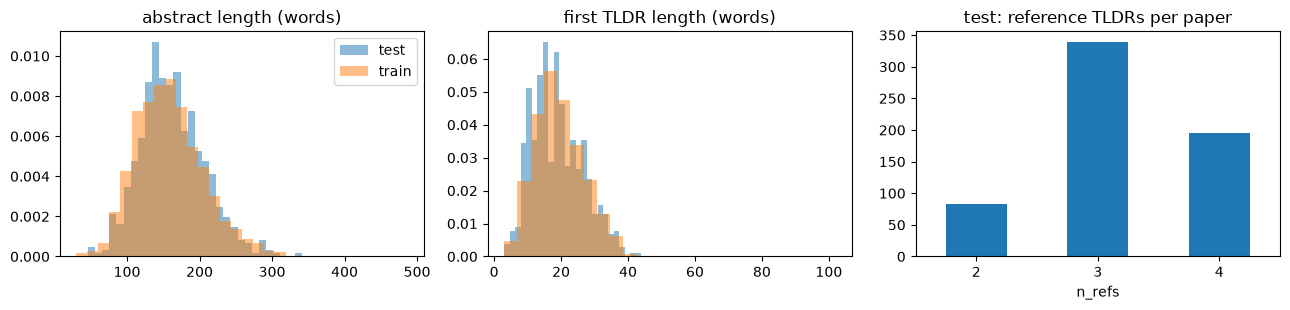


[Hyfn2jCcKm] Recently, Approximate Policy Iteration (API) algorithms have achieved super-human proficiency in two-player zero-sum games such as Go, Chess, and Shogi without human data. These API algorithms iterate between two policies: a slow policy (tree search), and a fast policy (a neural network). In these t...
   TLDR: We solve the Rubik's Cube with pure reinforcement learning
   TLDR: Solution to solving Rubik cube using reinforcement learning (RL) with Monte-Carlo tree search (MCTS) through autodidactic iteration.
   TLDR: This work solves Rubik's Cube using an approximate policy iteration method called Autodidactic iteration, overcoming the problem of sparse rewards by creating its own rewards system.
   TLDR: Introduces a deep RL algorithm to solve the Rubik's cube that handles the huge state space and very sparse reward of the Rubik's cube

[H1ziPjC5Fm] Visual Interpretation and explanation of deep models is critical towards wide adoption of systems that rely on them. In thi

In [5]:
display(papers.groupby("split").agg(
    n=("id", "size"), abstract_mean=("abstract_words", "mean"), abstract_max=("abstract_words", "max"),
    tldr_mean=("tldr_words", "mean"), tldr_max=("tldr_words", "max"), refs_per_paper=("n_refs", "mean")).round(1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for name, df in papers.groupby("split"):
    ax[0].hist(df.abstract_words, bins=30, alpha=.5, density=True, label=name)
    ax[1].hist(df.tldr_words, bins=25, alpha=.5, density=True, label=name)
test.n_refs.value_counts().sort_index().plot.bar(ax=ax[2], rot=0)
ax[0].set_title("abstract length (words)"); ax[1].set_title("first TLDR length (words)")
ax[2].set_title("test: reference TLDRs per paper"); ax[0].legend()
plt.tight_layout(); plt.show()

for _, r in test.sample(2, random_state=1).iterrows():
    print(f"\n[{r['id']}] {r['abstract'][:300]}...")
    for t in r["human_tldrs"]:
        print("   TLDR:", t)

## Token lengths vs the limits in the config
Inputs or targets longer than the limit are cut off during training.

In [6]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(CFG["train"]["model"])
src = pd.Series([len(x) for x in tok(train.abstract.tolist())["input_ids"]])
tgt = pd.Series([len(x) for x in tok(text_target=[t[0] for t in train.human_tldrs])["input_ids"]])
display(pd.DataFrame({"limit": [D["max_source_len"], D["max_target_len"]], "longest": [src.max(), tgt.max()],
                      "mean": [src.mean().round(1), tgt.mean().round(1)],
                      "cut off": [int((src > D["max_source_len"]).sum()), int((tgt > D["max_target_len"]).sum())]},
                     index=["abstract (tokens)", "TLDR (tokens)"]))

,limit,longest,mean,cut off
abstract (tokens),512,607,209.1,2
TLDR (tokens),64,136,27.4,4


## Save

In [7]:
for s in D["sizes"]:
    papers[papers.split == s][["id", "abstract", "human_tldrs"]].to_json(
        PROC / f"{s}.jsonl", orient="records", lines=True, force_ascii=False)
print("saved:", sorted(p.name for p in PROC.glob("*.jsonl")))

saved: ['test.jsonl', 'train.jsonl']
